In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
print("Pustaka pemodelan regresi berhasil dimuat.")

Pustaka pemodelan regresi berhasil dimuat.


In [2]:
# Memuat data cafe dan ulasan
path_cafes = '../outputs/cafes_preprocessed.csv'
if not os.path.exists(path_cafes):
    path_cafes = '../dataset/cafes.csv'
path_reviews = '../outputs/reviews_preprocessed.csv'
if not os.path.exists(path_reviews):
    path_reviews = '../dataset/reviews.csv'

df_cafes = pd.read_csv(path_cafes)
df_reviews = pd.read_csv(path_reviews)

if 'price_min_imputed' not in df_cafes.columns:
    df_cafes['price_min_imputed'] = df_cafes['price_min'].fillna(df_cafes['price_min'].median())
    df_cafes['price_max_imputed'] = df_cafes['price_max'].fillna(df_cafes['price_max'].median())

# Agregasi panjang rata-rata ulasan per cafe
rev_stats = df_reviews.groupby('cafe_id').agg(
    avg_text_len=('text', lambda x: np.mean([len(str(t)) for t in x])),
    avg_rev_rating=('rating', 'mean')
).reset_index()

df_reg = pd.merge(df_cafes, rev_stats, left_on='id', right_on='cafe_id')

features = ['review_count', 'price_min_imputed', 'price_max_imputed', 'avg_text_len']
target = 'rating'

X = df_reg[features].copy()
y = df_reg[target].copy()

print(f"Data Cafe untuk Regresi: {X.shape[0]} baris, {X.shape[1]} variabel prediktor")
print("Deskripsi Variabel Target (Rating Cafe):")
print(y.describe().round(3))

Data Cafe untuk Regresi: 271 baris, 4 variabel prediktor
Deskripsi Variabel Target (Rating Cafe):
count    271.000
mean       4.658
std        0.248
min        3.200
25%        4.500
50%        4.700
75%        4.800
max        5.000
Name: rating, dtype: float64


In [3]:
# Pembagian 80% train dan 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Standardisasi fitur untuk SVR (SVR sangat sensitif terhadap magnitudo skala fitur)
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)

print(f"Dimensi Data Latih : {X_train.shape}")
print(f"Dimensi Data Uji   : {X_test.shape}")

Dimensi Data Latih : (216, 4)
Dimensi Data Uji   : (55, 4)


In [4]:
# Inisialisasi model
model_lr = LinearRegression()
model_svr_rbf = SVR(kernel='rbf', C=10.0, epsilon=0.1)
model_svr_lin = SVR(kernel='linear', C=1.0, epsilon=0.1)

# Training model
model_lr.fit(X_train, y_train)
model_svr_rbf.fit(X_train_scaled, y_train)
model_svr_lin.fit(X_train_scaled, y_train)

# Prediksi pada testing set
y_pred_lr = model_lr.predict(X_test)
y_pred_svr_rbf = model_svr_rbf.predict(X_test_scaled)
y_pred_svr_lin = model_svr_lin.predict(X_test_scaled)

print("Koefisien Model Linear Regression:")
for feat, coef in zip(features, model_lr.coef_):
    print(f"- {feat:20s}: {coef:+.6f}")
print(f"- Intercept           : {model_lr.intercept_:.4f}")

Koefisien Model Linear Regression:
- review_count        : -0.000016
- price_min_imputed   : -0.000000
- price_max_imputed   : +0.000002
- avg_text_len        : -0.001381
- Intercept           : 4.7736


In [5]:
# Fungsi evaluasi metrik regresi
def hitung_metrik(y_true, y_pred, nama_model):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {'Model': nama_model, 'MAE': round(mae, 4), 'MSE': round(mse, 4), 'RMSE': round(rmse, 4), 'R2_Score': round(r2, 4)}

eval_results = [
    hitung_metrik(y_test, y_pred_lr, 'Linear Regression'),
    hitung_metrik(y_test, y_pred_svr_rbf, 'SVR (RBF Kernel)'),
    hitung_metrik(y_test, y_pred_svr_lin, 'SVR (Linear Kernel)')
]

df_eval_reg = pd.DataFrame(eval_results)
print("=== TABEL EVALUASI KOMPARASI PERFORMA MODEL REGRESI ===")
print(df_eval_reg.to_string(index=False))

=== TABEL EVALUASI KOMPARASI PERFORMA MODEL REGRESI ===
              Model    MAE    MSE   RMSE  R2_Score
  Linear Regression 0.1946 0.0824 0.2870   -0.0376
   SVR (RBF Kernel) 0.2040 0.0931 0.3051   -0.1724
SVR (Linear Kernel) 0.1892 0.0825 0.2872   -0.0386


<string>:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



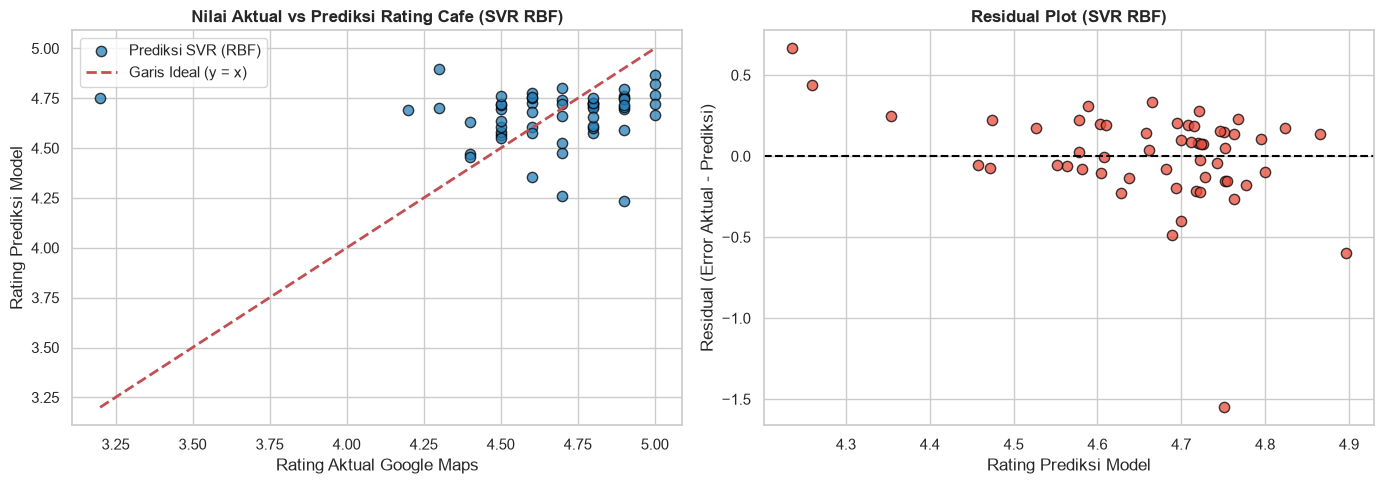

In [6]:
plt.figure(figsize=(14, 5))

# Subplot 1: Nilai Aktual vs Prediksi
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_svr_rbf, color='#2980b9', alpha=0.75, edgecolors='black', s=55, label='Prediksi SVR (RBF)')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', linewidth=2, label='Garis Ideal (y = x)')
plt.title('Nilai Aktual vs Prediksi Rating Cafe (SVR RBF)', fontsize=12, fontweight='bold')
plt.xlabel('Rating Aktual Google Maps')
plt.ylabel('Rating Prediksi Model')
plt.legend()

# Subplot 2: Residual Plot
plt.subplot(1, 2, 2)
residual_svr = y_test - y_pred_svr_rbf
plt.scatter(y_pred_svr_rbf, residual_svr, color='#e74c3c', alpha=0.75, edgecolors='black', s=55)
plt.axhline(0, color='black', linestyle='--', linewidth=1.5)
plt.title('Residual Plot (SVR RBF)', fontsize=12, fontweight='bold')
plt.xlabel('Rating Prediksi Model')
plt.ylabel('Residual (Error Aktual - Prediksi)')

plt.tight_layout()
plt.show()

In [7]:
import joblib

os.makedirs('../outputs', exist_ok=True)
path_model_reg = '../outputs/svr_rating_predictor_js7.joblib'
joblib.dump({'model': model_svr_rbf, 'scaler': scaler_X, 'features': features}, path_model_reg)

df_eval_reg.to_csv('../outputs/regresi_evaluasi_js7.csv', index=False)
print(f"Model SVR dan Scaler berhasil disimpan ke: {path_model_reg}")

Model SVR dan Scaler berhasil disimpan ke: ../outputs/svr_rating_predictor_js7.joblib
